# Convolution - Calculation with Functions (Selectable)

> Part of *PHYS 0241: Biomedical Imaging* (Prof. Michael E. Durst, Middlebury College). The [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch05/ch05-08.html) shows the rendered version together with the pre-rendered animations (course password required).
>
> **Start here:** no setup is needed for this notebook. In Google Colab, choose **File > Save a copy in Drive** to keep your changes.
>
> *Provided for academic use in PHYS 0241; please do not repost or redistribute ([terms of use](https://github.com/durstme/textbook-biomedicalimaging-notebooks/blob/main/LICENSE.md)).*

## Import libraries

In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
%matplotlib inline
# Define global "bold" style parameters
# This restores the thicker lines and fonts seen in older versions
plot_params = {
    # --- Fonts ---
    'font.size': 18,
    'font.family': 'sans-serif',
    
    # --- Axes (The Box) ---
    'axes.linewidth': 1.0,       # Thicker box around the plot
    
    # --- Lines (The Signal) ---
    'lines.linewidth': 2.5,      # Thicker default plot lines
}

# Apply these settings globally
plt.rcParams.update(plot_params)

## Define parameters

In [4]:
# ==========================================
# 1. Define ARBITRARY Input Shapes
# ==========================================
def get_f(t):
    """
    Input shape f(t). 
    Currently set to: Rectangle from 1 to 2.
    """
    # Using np.where to allow array inputs
    return np.where((t >= 1) & (t <= 2), 2.0, 0.0)

def get_g(t):
    """
    Input shape g(t).
    Currently set to: Ramp from 0 to 5.
    """
    return np.where((t >= 0) & (t <= 5), (2.0/5.0) * t, 0.0)

# ==========================================
# 2. Perform The "Actual" Convolution
# ==========================================

# Define time resolution and grid
dt = 0.01
# We need a wide grid to ensure the signals die down to zero
t_grid = np.arange(-10, 20, dt) 

# Create the numerical arrays for the shapes
f_arr = get_f(t_grid)
g_arr = get_g(t_grid)

# Calculate Convolution using NumPy's built-in signal processing function
# 'full' returns the complete convolution (size N + M - 1)
h_arr = np.convolve(f_arr, g_arr, mode='full') * dt

# Construct the correct time axis for the resulting convolution
# The start time of a convolution is t_start_f + t_start_g
t_start_h = t_grid[0] + t_grid[0]
t_h = np.arange(len(h_arr)) * dt + t_start_h

# ==========================================
# 3. Setup Visualization for Delay T
# ==========================================

# Choose a specific delay T to visualize
T = 5

# To plot the overlap step f(tau) * g(T-tau), we need to compute g(T-tau).
# We can do this by interpolating the original function or array.
# Here we use the function definition for cleanest "sliding" visualization.
tau = t_grid  # Integration variable axis
f_tau = get_f(tau)
g_shifted = get_g(T - tau) # The flipped and shifted g

# Calculate the specific product for this T
product = f_tau * g_shifted
current_area = np.trapezoid(product, tau) # This should equal h(T)


## Plot

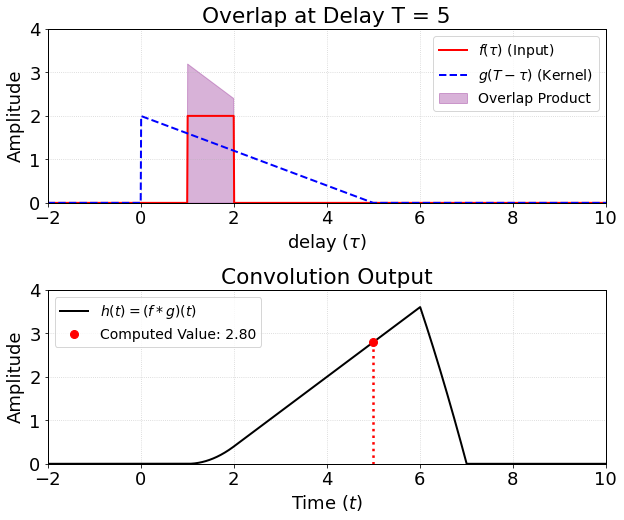

In [9]:
# ==========================================
# 4. Plotting
# ==========================================

fig1, (axes11, axes12) = plt.subplots(2, 1, figsize=(10, 8))
plt.subplots_adjust(hspace=0.5)

# --- Top Plot: The Physical Overlap ---
axes11.plot(tau, f_tau, 'r-', linewidth=2, label=r'$f(\tau)$ (Input)')
axes11.plot(tau, g_shifted, 'b--', linewidth=2, label=r'$g(T - \tau)$ (Kernel)')
axes11.fill_between(tau, product, color='purple', alpha=0.3, label='Overlap Product')

axes11.set_title(f'Overlap at Delay T = {T}')
axes11.set_xlabel(r'delay $(\tau)$')
axes11.set_ylabel('Amplitude')
axes11.legend(loc='upper right', fontsize=14)
axes11.grid(True, linestyle=':', alpha=0.6)
axes11.set_xlim(-2, 10)
axes11.set_ylim(0, 4.0)

# --- Bottom Plot: The Convolution Result ---
axes12.plot(t_h, h_arr, 'k-', linewidth=2, label=r'$h(t) = (f * g)(t)$')

# Plot the specific point T
# We interp to find the exact y-value on the h_arr curve at x=T
h_val_at_T = np.interp(T, t_h, h_arr)
axes12.plot(T, h_val_at_T, 'ro', markersize=8, label=f'Computed Value: {h_val_at_T:.2f}')
axes12.vlines(T, 0, h_val_at_T, colors='r', linestyles=':')

axes12.set_title('Convolution Output')
axes12.set_xlabel(r'Time $(t)$')
axes12.set_ylabel('Amplitude')
axes12.legend(loc='upper left', fontsize=14)
axes12.grid(True, linestyle=':', alpha=0.6)
axes12.set_xlim(-2, 10)
axes12.set_ylim(0, 4.0)

plt.show()

### Save plot

In [ ]:
# fig1.savefig("../figures/ch05/ch05-08.jpg", dpi=300, bbox_inches='tight')

## Make interactive with ipywidgets

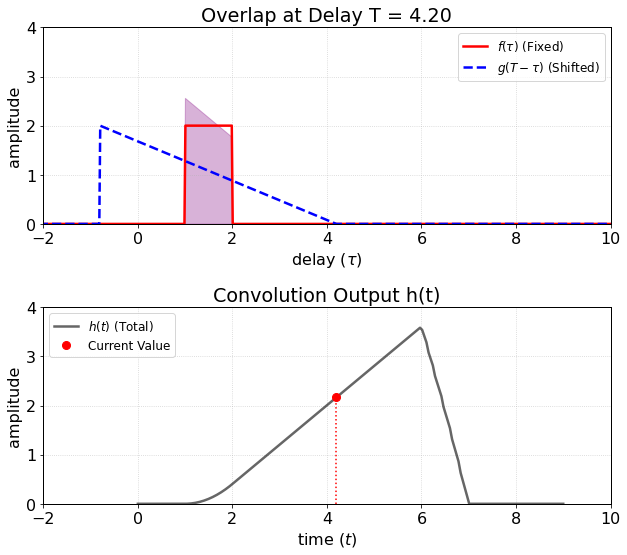

In [11]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
import ipywidgets as widgets
from IPython.display import display, clear_output

# --- 1. Global Style Settings ---
plot_params = {
    'font.size': 16,
    'font.family': 'sans-serif',
    'axes.linewidth': 1.0,
    'lines.linewidth': 2.5,
    'figure.autolayout': True,
}
plt.rcParams.update(plot_params)

# --- 2. Define Math Functions ---
def f0(t):
    return np.where((t >= 1) & (t <= 2), 2.0, 0.0)

def g0(t):
    return np.where((t >= 0) & (t <= 5), (2.0/5.0) * t, 0.0)

# --- 3. Pre-calculate Static Data (The Background Curve) ---
# We calculate h(t) once for the whole range so the bottom plot background is ready
tau_grid = np.linspace(-5, 15, 1000) # High res for integration
t_range = np.linspace(0, 9, 200)     # Range for the result plot

# Compute the full convolution curve h(t) upfront
h_curve = []
for t in t_range:
    # Integration: Area of f(tau) * g(t - tau)
    val = np.trapezoid(f0(tau_grid) * g0(t - tau_grid), tau_grid)
    h_curve.append(val)

# --- 4. Setup Figure and Axes Objects (Object Oriented) ---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 8))
plt.subplots_adjust(hspace=0.4)
fig.canvas.header_visible = False # Hide header

# -- Top Plot: The Overlap Process --
# Static f(tau)
ax1.plot(tau_grid, f0(tau_grid), 'r-', label=r'$f(\tau)$ (Fixed)')
# Dynamic placeholders (we initialize them empty)
line_g, = ax1.plot([], [], 'b--', label=r'$g(T - \tau)$ (Shifted)')
# We will handle fill_between in the update function by keeping a reference
fill_collection = None 

ax1.set_title('Overlap at Delay T')
ax1.set_xlabel(r'delay $(\tau)$')
ax1.set_ylabel('amplitude')
ax1.legend(loc='upper right', fontsize=12)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.set_xlim(-2, 10)
ax1.set_ylim(0, 4)

# -- Bottom Plot: The Result h(t) --
# Static h(t) curve
ax2.plot(t_range, h_curve, 'k-', alpha=0.6, label=r'$h(t)$ (Total)')
# Dynamic point and drop line
line_dot, = ax2.plot([], [], 'ro', markersize=8, label='Current Value')
line_vert, = ax2.plot([], [], 'r:', linewidth=1.5)

ax2.set_title('Convolution Output h(t)')
ax2.set_xlabel(r'time $(t)$')
ax2.set_ylabel('amplitude')
ax2.legend(loc='upper left', fontsize=12)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.set_xlim(-2, 10)
ax2.set_ylim(0, 4)

# Prevent the static figure from displaying twice
plt.close(fig) 

# --- 5. The Optimized Update Function ---
def update_plot(T):
    global fill_collection
    
    # A. Calculate Dynamic Data
    # Shift g by T
    g_shifted = g0(T - tau_grid)
    # Product for the shaded area
    product = f0(tau_grid) * g_shifted
    # Resulting scalar value h(T)
    h_val = np.trapezoid(product, tau_grid)
    
    # B. Update Artists (Top Plot)
    line_g.set_data(tau_grid, g_shifted)
    
    # Efficiently update fill_between by removing the old one and adding new
    if fill_collection:
        fill_collection.remove()
    fill_collection = ax1.fill_between(tau_grid, product, color='purple', alpha=0.3)
    
    ax1.set_title(f'Overlap at Delay T = {T:.2f}')

    # C. Update Artists (Bottom Plot)
    line_dot.set_data([T], [h_val])
    line_vert.set_data([T, T], [0, h_val]) # Draw vertical line
    
    return line_g, fill_collection, line_dot, line_vert

# --- 6. Interactive Widget ---
def on_slider_change(change):
    update_plot(change['new'])
    # This pattern works best with %matplotlib inline to simulate animation
    clear_output(wait=True)
    display(fig)

slider = widgets.FloatSlider(
    value=0.0, min=0.0, max=9.0, step=0.1, 
    description='Delay T:', layout=widgets.Layout(width='60%')
)
slider.observe(on_slider_change, names='value')

# Trigger initial display
on_slider_change({'new': 0.0})
display(slider)

### Save animation as mp4 movie file

In [ ]:
import matplotlib.animation as animation

# Setup the writer (requires ffmpeg installed on the system)
Writer = animation.writers['ffmpeg']
writer = Writer(fps=20, metadata=dict(artist='Me'), bitrate=1800)

# Create a sequence of T values to animate
frames = np.linspace(0, 9, 180) # 9 seconds at 20fps

def animate_frame(i):
    T = frames[i]
    # Reuse the exact same update logic from the previous cell
    return update_plot(T)

print("Generating animation... (this may take a moment)")

# Create Animation object
# blit=False is safer for 'fill_between' updates in some matplotlib versions
anim = animation.FuncAnimation(fig, animate_frame, frames=len(frames), interval=50, blit=False)

# Save to file
# anim.save('../../animations/ch05/ch05-08.mp4', writer=writer)
# print("Movie saved as convolution_demo.mp4")

Generating animation... (this may take a moment)
Movie saved as convolution_demo.mp4


### Display animation with javascript from standalone html
[Link to animation](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch05/ch05-08_animation.html)

*Animation.* The pre-rendered animation for this section is shown on the [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch05/ch05-08.html) (direct link: [ch05-08_animation.html](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch05/ch05-08_animation.html)). It is not embedded here because Colab cannot load files from the textbook site; running the code above produces the live version.